In [1]:
%config InlineBackend.figure_format = 'svg'

import numpy as np
import matplotlib.pyplot as plt

from typing import Tuple
from numpy.typing import NDArray

In [2]:
x = np.array([1, 2, 2.5])
y = np.array([1, 2, 3])

In [3]:
wheelbase = 0.25
initial_vehicle_orientation = 0.0 * np.pi
initial_vehicle_position = (1.8, 1.1)
look_ahead_distance = 0.75

In [4]:
def plot_circle(center: Tuple[float, float], radius: float) -> None:
    rads = np.linspace(0, 2 * np.pi, 100)
    x_ = radius * np.cos(rads) + center[0]
    y_ = radius * np.sin(rads) + center[1]
    plt.plot(x_, y_, ls='--', color='black', alpha=0.3)

In [5]:
def plot_car(rear_axel_position: Tuple[float, float] | NDArray, vehicle_orientation: float) -> None:
    front_axel_position = rear_axel_position + wheelbase * np.array([np.cos(vehicle_orientation), np.sin(vehicle_orientation)])
    plt.plot([rear_axel_position[0], front_axel_position[0]], [rear_axel_position[1], front_axel_position[1]], c='r')

In [6]:
def get_eta(x_0, x_1, c, l_1):
    d = x_1 - x_0
    r = x_0 - c

    square_root = np.sqrt(np.dot(r, d) ** 2 - np.dot(d, d) * (np.dot(r, r) - l_1 ** 2))

    t_1 = (-np.dot(r, d) + square_root) / np.dot(d, d)
    t_2 = (-np.dot(r, d) - square_root) / np.dot(d, d)

    phi_1 = np.arctan2(r[1] + t_1 * d[1], r[0] + t_1 * d[0])
    phi_2 = np.arctan2(r[1] + t_2 * d[1], r[0] + t_2 * d[0])

    return phi_1, phi_2

phis = get_eta(np.array([x[0], y[0]]), np.array([x[1], y[1]]), initial_vehicle_position, look_ahead_distance)
print(phis)

(1.506172106256753, -3.0769684330516496)


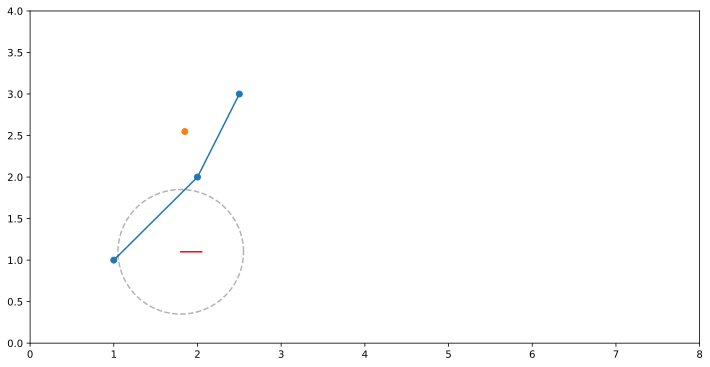

In [7]:
plt.figure(figsize=(12, 6), dpi=200)
plt.scatter(x, y)
plt.plot(x, y)

plot_circle(initial_vehicle_position, look_ahead_distance)

plot_car(initial_vehicle_position, initial_vehicle_orientation)

# plt.annotate(
#     "My label",
#     xy=(1, 1),    # Arrow tip
#     xytext=(0.5, 0.5),            # Arrow start
#     arrowprops=dict(arrowstyle="->", color="blue"),
# )

plt.scatter(initial_vehicle_position[0] + np.cos(phis[0]) * look_ahead_distance, initial_vehicle_position[0] + np.sin(phis[0]) * look_ahead_distance)

plt.xlim(0, 8)
plt.ylim(0, 4)
plt.show()